In [1]:
import os
%load_ext autoreload
%autoreload 1
%aimport utility.functions
%aimport src.analysis
%aimport src.dataset
%aimport src.plots
%aimport src.simulation
import numpy as np
import utility.functions as fn
import src.simulation as sim
import src.analysis as an
import src.dataset as ds
import src.plots as plots
import torch
from scipy.stats import norm
import pandas as pd
from utility.double_beta_spectrum import pdf_ratio2b
import matplotlib.pyplot as plt
channels = [3, 5, 9, 11, 13, 15, 17, 19]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]

In [ ]:

# Initialize output DataFrame
out_data = pd.DataFrame(columns=["channel_ID", "channel", "acceptance", "BI", "rp","J"])
out_data.to_csv('../outputs/BI_results_interp.csv', index=False)
n_deriv = 1

for index_channel in np.argsort(channel_ID):
    channel = channels[index_channel]
    
    # Load datasets and channel specifications
    data_single, data_pileup, _, _, _ = ds.create_data_sets(channel, win_length=2000, shift=0, pos_prefix="_bis")
    #data_single, data_pileup = ds.create_data_sets_denoise(channel, win_length=2000, shift=0, pos_prefix="_bis")
    H_unit, S, nps, w, pulse_factor = ds.get_channel_specs(channel, n_deriv=n_deriv, window_fct = np.hanning) #, nps_name="denoised_noise"
    
    signal_amp = ds.get_amp_Q_val(channel)*pulse_factor
    t_min, t_max, N_t = 0, 8e-4, 100
    r_min, r_max, N_r = 0., .5, 25
    
    ratio_distribution = pdf_ratio2b(np.linspace(r_min, r_max, N_r))
    ratio_distribution /= np.mean(ratio_distribution)
    
    # Convert data to PyTorch tensors
    S_torch = torch.tensor(S, dtype=torch.cfloat)
    H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat)
    w_torch = torch.tensor(w, dtype=torch.cfloat)
    t_torch = torch.linspace(t_min, t_max,N_t, dtype=torch.cfloat)
    r_torch = torch.linspace(r_min, r_max, N_r, dtype=torch.cfloat)
    nps_torch = torch.tensor(nps, dtype=torch.cfloat)
    signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32)
    ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat)

    # Loop over acceptance levels
    # acceptances = [0.7, 0.8, 0.84, 0.87, 0.9, 0.92, 0.93, 0.94, 0.95, 0.96, 0.99]
    acceptances = [0.9]
    for acceptance in acceptances:
        N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
        f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500)
        #save_filter_function 
        np.save(f"../outputs/training_Js/channel_{channel}/J_{int(acceptance*100):d}_V3", np.array(J_values))
        np.save(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance*100):d}_V3", np.array([f1_opt, f2_opt]))
        # Compute PSD and BI
        rp, BI = an.compute_BI(data_pileup, data_single, acceptance, H_unit, f1_opt, f2_opt,window_fct = np.hanning,n_deriv = n_deriv)
        # Append results to DataFrame
        out_data = pd.concat([out_data, pd.DataFrame([{"channel_ID": channel_ID[index_channel], "channel": channel, 
                                                       "acceptance": acceptance, "BI": BI, "rp": rp, "J": J_values[-1]}])], ignore_index=True)
        # Save results to CSV
        out_data.to_csv('../outputs/BI_results_interp_v3.csv', index=False)
        print(f"Channel {channel}, Acceptance {acceptance}: J={J_values[-1]}, 1-rp={1-rp}, BI={BI}")

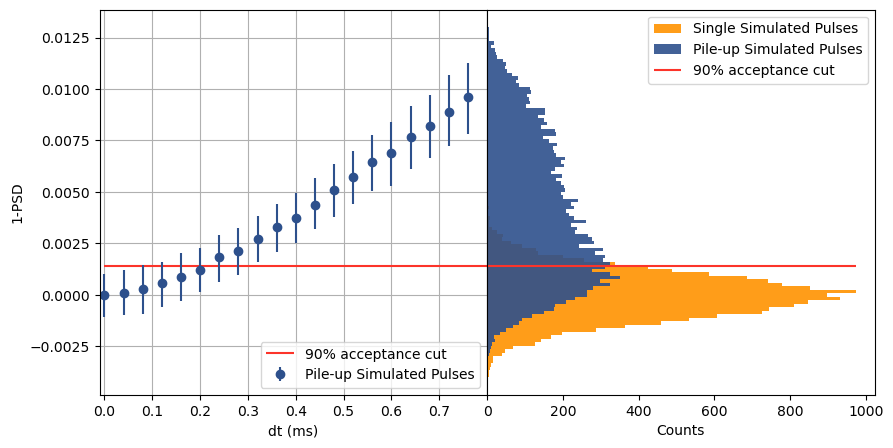

In [88]:
fig, ax, ax2 = plots.plot_psd_vs_dt(PSD_single, PSD_pileup, dt_pileup, cut=cut, bins=20,PSD_min=-0.004,PSD_max =0.013)
# ax.set_ylim(0.985,1.005)
ax.grid()

# ax2.grid()

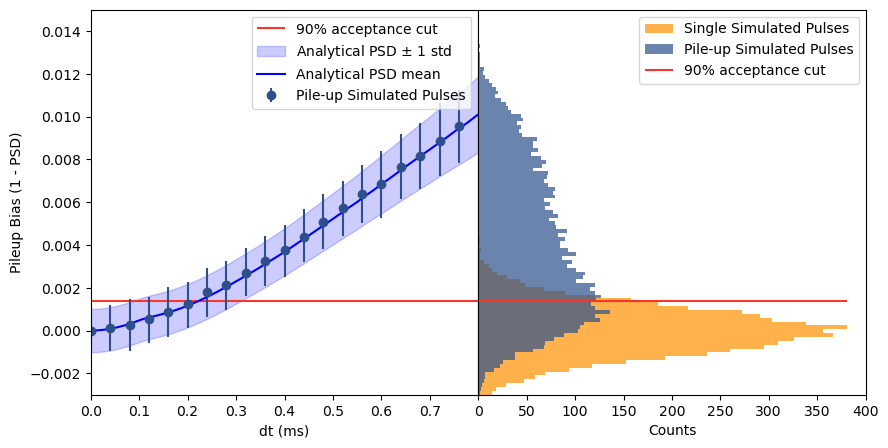

In [87]:
from src.plots import plot_biais_vs_dt
import matplotlib.pyplot as plt
S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
f1_opt, f2_opt = np.load(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff90_V3.npy")
f1,f2  = torch.tensor(f1_opt,dtype=torch.cfloat), torch.tensor(f2_opt,dtype=torch.cfloat)
muY, sigmaY, mu1, mu2, var1, var2, cov12= an.compute_mu_sigma(f1, f2, S_H_delayed,r_torch, S_H, S2_over_nps, signal_amp, return_all=True)
mu = torch.mean(ratio_distribution_torch[:,None]*(1-muY.real), dim = 0).numpy().real
sigma = torch.sqrt(torch.mean(ratio_distribution_torch[:,None]*sigmaY**2, dim = 0)+torch.mean(ratio_distribution_torch[:,None]*(1-muY.real)**2, dim = 0)-mu**2).numpy().real
fig,ax,ax1=plot_biais_vs_dt(PSD_single.real, PSD_pileup.real, dt_pileup,cut=1-cut,bins=20)
ax.fill_between(t_torch.numpy().real*1e3, (mu-sigma).real, (mu+sigma).real, alpha=0.2, color='blue', label='Analytical PSD $\pm$ 1 std')
ax.plot(t_torch.numpy().real*1e3, mu.real, color='blue', label='Analytical PSD mean')
ax.set_xlim(0,0.8)
ax.set_ylim(-0.003,0.015)
ax.legend()
plt.show()

In [ ]:
from torch.utils.data import TensorDataset
n_deriv = 1
channel = 15
H_unit, S, nps, w, pulse_factor = ds.get_channel_specs(channel, n_deriv=n_deriv, window_fct = np.hanning)
f1_opt, f2_opt = np.load(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff90_V3.npy")
fpulses, signal_freq, noise_freq, generated_r, generated_dt_single = sim.simulate_frequency_pulses(S,nps,8.59898e-05,w,signal_scale = 0.001874,nsim=10000,dt_max=0)
dataset_simu = TensorDataset(torch.from_numpy(np.fft.ifft(fpulses, axis=1).real.astype(np.float32)))
PSD_simu_single,_, _ = an.get_PSD_interpole(dataset_simu, H_unit, f1_opt, f2_opt)
fpulses, signal_freq, noise_freq, generated_r, generated_dt = sim.simulate_frequency_pulses(S,nps,8.59898e-05,w,signal_scale = 0.001874,nsim=10000)
dataset_simu = TensorDataset(torch.from_numpy(np.fft.ifft(fpulses, axis=1).real.astype(np.float32)))
PSD_simu,Amp_1_simu, Amp_2_simu = an.get_PSD_interpole(dataset_simu, H_unit, f1_opt, f2_opt)


In [26]:
from src.simulation import bessel_filter_coeffs, filtered_pulse_model, pulse_model
from lmfit import Model
from scipy.signal import freqz

freq = np.fft.rfftfreq(2000, d=1e-4)  # Hz
omega = 2 * np.pi * freq  # rad/s
fs = 1e4
t = np.arange(0,2000)/fs
n_deriv = 0
acceptance = 0.9
N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)

model = Model(filtered_pulse_model,independent_vars=['t'],param_names=['A','t0','tau_rise','tau_decay1','tau_decay2','p'])
params = model.make_params(A=1,t0=0.1, tau_rise=1e-4,tau_decay1=1e-3,tau_decay2=2e-3,p=0.5)

_, h_bessel_small_2500 = freqz(*bessel_filter_coeffs(6, 2500, 1e4), worN=1001)
h_bessel_2500 = np.concatenate([h_bessel_small_2500, np.conj(h_bessel_small_2500[1:1000][::-1])])

for channel in [9]:    
    H_unit, S, nps, w, pulse_factor = ds.get_channel_specs(channel, n_deriv=0, window_fct = np.hanning)
    
    result = model.fit(np.fft.ifft(S),params,t=t, order=6,fc=2500,nan_policy='omit')  
    S_no_filter = np.fft.fft(pulse_model(t, **result.params))
    
    w_torch = torch.tensor(w, dtype=torch.cfloat)
    t_torch = torch.linspace(0, 8e-4, 100, dtype=torch.cfloat)
    r_torch = torch.linspace(0., .5, 25, dtype=torch.cfloat)
    signal_amp = ds.get_amp_Q_val(channel)*pulse_factor
    signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32)
    ratio_distribution = pdf_ratio2b(r_torch.numpy())
    ratio_distribution /= np.mean(ratio_distribution)
    ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat)
    
    fcs = [500,750,1000, 1500, 2000, 2500, 3000,3500,4000,4500]
    # fcs = [2500]
    fcts =[]
    Js =[]
    for idx,fc in enumerate(fcs):
        _, h_bessel_small = freqz(*bessel_filter_coeffs(6, fc, 1e4), worN=1001)
        h_bessel = np.concatenate([h_bessel_small, np.conj(h_bessel_small[1:1000][::-1])])
        
        S_bis = S * h_bessel/h_bessel_2500 #S_no_filter * h_bessel 
        nps_bis = nps * np.abs(h_bessel/h_bessel_2500)
        H_bis = np.conj(S_bis) / nps_bis
        H_unit_bis = H_bis / np.mean(np.abs(H_bis * S_bis))
        
        S_torch = torch.tensor(S_bis, dtype=torch.cfloat)
        nps_torch = torch.tensor(nps_bis, dtype=torch.cfloat)
        H_unit_torch = torch.tensor(H_unit_bis, dtype=torch.cfloat)
        
        f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500, verbose=False)
        
        np.save(f"../outputs/Pileup_filter_functions/channel_{channel}/bessel_study/functions_fc_{fc}_real_S", np.array([f1_opt, f2_opt ]))
        
        fcts.append((f1_opt, f2_opt))
        Js.append(J_values[-1])
plt.plot(fcs, 1-np.array(Js), marker='o')
plt.xlabel('Bessel Filter Cutoff Frequency (Hz)')
plt.ylabel('1-J aka "rejection power"')   

KeyboardInterrupt: 